# Phase 6: End-to-End LLM QA Evaluation

**Goal**: Evaluate GRL-RAG retrieval paths with LLMs to measure final QA accuracy, directly comparable with GNN-RAG paper (Tables 1 & 5).

### Pipeline
1. Load P4b trained retrievers (Selection RL, Traversal RL, GreedyGNN)
2. Run retrieval on test set → get reasoning paths per question
3. Build prompts (matching GNN-RAG paper's format exactly)
4. Call LLM → extract answers
5. Evaluate: Hit, F1, Accuracy (using GNN-RAG paper's evaluation code)

### LLMs (matching paper Table 5)
- **Llama-2-Chat-7B** (`meta-llama/Llama-2-7b-chat-hf`) — primary, local on A100
- **Flan-T5-xl** (`google/flan-t5-xl`) — smaller alternative
- **ChatGPT** (`gpt-3.5-turbo`) — API-based (optional, requires paid billing)

### Paper comparison targets (WebQSP, from Table 5)
| Method | LLM | Hit |
|--------|-----|-----|
| GNN-RAG | Llama2-Chat-7B (RoG) | 85.2 |
| GNN-RAG | ChatGPT | 85.3 |
| GNN-RAG | Flan-T5-xl | 74.5 |
| GNN-RAG+RA | Llama2-Chat-7B (RoG) | 90.7 |

### Our results so far
| Method | LLM | Hit | Avg Cost |
|--------|-----|-----|----------|
| GNN-RAG (ours) | Flan-T5-xl | 73.9 | 6.5 |
| GRL-RAG Selection RL | Flan-T5-xl | 72.1 | 5.1 |
| GRL-RAG Traversal RL | Flan-T5-xl | 60.4 | 8.9 |

In [27]:
# === Cell 1: Setup & Installs ===
!pip install -q transformers accelerate sentencepiece protobuf tiktoken
!pip install -q openai  # For ChatGPT (optional)

from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.insert(0, '/content/drive/MyDrive/ThS/Research/colab/graph_rag')
from common import *

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pickle
import json
import os
import re
import string
import time
from tqdm import tqdm

# Directories (from common.py)
print(f'CHECKPOINT_DIR: {CHECKPOINT_DIR}')
print(f'RESULTS_DIR: {RESULTS_DIR}')

# P6 output directory
P6_DIR = os.path.join(RESULTS_DIR, 'p6_llm_eval')
os.makedirs(P6_DIR, exist_ok=True)
print(f'P6_DIR: {P6_DIR}')

# OpenAI API key — set via Colab secrets or environment variable
# Option 1: Colab secrets (recommended)
# from google.colab import userdata
# API_KEY = userdata.get('OPENAI_API_KEY')
# Option 2: Set manually (DO NOT commit to git!)
API_KEY = None  # <-- Set your OpenAI key here if needed

# Prediction file paths (used across cells)
PRED_FILE_LLAMA = os.path.join(P6_DIR, 'predictions_llama2.jsonl')
PRED_FILE_FLAN = os.path.join(P6_DIR, 'predictions_flan_t5.jsonl')
PRED_FILE_GPT = os.path.join(P6_DIR, 'predictions_chatgpt.jsonl')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CHECKPOINT_DIR: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/checkpoints
RESULTS_DIR: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results
P6_DIR: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/p6_llm_eval


In [28]:
# === Cell 2: Import grl_rag & Load Data ===
import sys, os, shutil, importlib

GRL_RAG_PATH = '/content/drive/MyDrive/ThS/Research/colab/graph_rag'
GRL_RAG_FILE = os.path.join(GRL_RAG_PATH, 'grl_rag.py')

assert os.path.exists(GRL_RAG_FILE), f'File not found: {GRL_RAG_FILE}'
print(f'grl_rag.py found: {os.path.getsize(GRL_RAG_FILE)} bytes')

pycache = os.path.join(GRL_RAG_PATH, '__pycache__')
if os.path.exists(pycache):
    shutil.rmtree(pycache)
to_del = [k for k in sys.modules if 'grl_rag' in k]
for k in to_del:
    del sys.modules[k]
if GRL_RAG_PATH not in sys.path:
    sys.path.insert(0, GRL_RAG_PATH)

from grl_rag import *
print('grl_rag imported OK')

# --- Load test GNN features ---
gnn_test = GNNHeuristic(os.path.join(CHECKPOINT_DIR, 'gnn_features_test.pkl'))
print(f'Test features: {len(gnn_test.features)} questions')

# --- Embedder ---
EMB_CACHE = os.path.join(CHECKPOINT_DIR, 'embeddings_cache.pkl')
embedder = Embedder(cache_path=EMB_CACHE)
EMB_DIM = embedder.emb_dim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# --- Hotfix: patch device mismatch (same as P4b cell 13) ---
def _fixed_encode_actions(self, actions):
    entity_embs, relation_embs, scores = [], [], []
    for rel, entity, rel_text, gnn_score in actions:
        if entity is None:
            entity_embs.append(self.policy.stop_entity_emb.detach().cpu())
            relation_embs.append(self.policy.stop_relation_emb.detach().cpu())
        else:
            entity_embs.append(self.embedder.encode(entity))
            relation_embs.append(self.embedder.encode(rel_text))
        scores.append(gnn_score)
    return (torch.stack([e.cpu() for e in entity_embs]).unsqueeze(0).to(self.device),
            torch.stack([e.cpu() for e in relation_embs]).unsqueeze(0).to(self.device),
            torch.tensor(scores).unsqueeze(0).unsqueeze(-1).float().to(self.device))

TraversalRetriever._encode_actions = _fixed_encode_actions
print('Patched _encode_actions')

# --- Load trained policies ---
# Selection RL
policy_selection = PathSelectionPolicy(emb_dim=EMB_DIM).to(device)
sel_ckpt_path = os.path.join(CHECKPOINT_DIR, 'rl_epoch5.pt')
# Try selection-specific checkpoint first, then generic
for candidate in ['selection_rl_epoch5.pt', 'rl_epoch5.pt']:
    p = os.path.join(CHECKPOINT_DIR, candidate)
    if os.path.exists(p):
        sel_ckpt_path = p
        break

# Traversal RL
policy_traversal = TraversalPolicy(emb_dim=EMB_DIM).to(device)
trav_ckpt_path = os.path.join(CHECKPOINT_DIR, 'traversal_pretrain_e10.pt')
for candidate in ['traversal_rl_epoch5.pt', 'traversal_pretrain_e10.pt']:
    p = os.path.join(CHECKPOINT_DIR, candidate)
    if os.path.exists(p):
        trav_ckpt_path = p
        break

print(f'\nLoading Selection RL from: {os.path.basename(sel_ckpt_path)}')
sel_ckpt = torch.load(sel_ckpt_path, map_location=device)
policy_selection.load_state_dict(sel_ckpt['model_state'])
print(f'  Epoch: {sel_ckpt.get("epoch", "?")}')

print(f'Loading Traversal RL from: {os.path.basename(trav_ckpt_path)}')
trav_ckpt = torch.load(trav_ckpt_path, map_location=device)
policy_traversal.load_state_dict(trav_ckpt['model_state'])
print(f'  Epoch: {trav_ckpt.get("epoch", "?")}')

# Build retrievers
greedy_retriever = GreedyGNNRetriever(gnn_test, max_steps=5, budget=50)
traversal_retriever = TraversalRetriever(
    gnn_test, policy_traversal, embedder,
    max_steps=10, budget=50, device=device
)
selection_retriever = PathSelectionRetriever(
    gnn_test, policy_selection, embedder,
    max_paths=10, device=device
)

print('\nAll retrievers ready.')

grl_rag.py found: 22431 bytes
grl_rag imported OK
Loaded GNN features for 1639 questions
Test features: 1639 questions


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda
Patched _encode_actions

Loading Selection RL from: selection_rl_epoch5.pt
  Epoch: 5
Loading Traversal RL from: traversal_rl_epoch5.pt
  Epoch: 5

All retrievers ready.


In [29]:
# === Cell 3: Prompt Builder (matching GNN-RAG paper exactly) ===

# Instruction from GNN-RAG paper (build_qa_input.py line 30)
SAQ_RULE_INSTRUCTION = """Based on the reasoning paths, please answer the given question. Please keep the answer as simple as possible and return all the possible answers as a list."""

# Prompt templates matching paper's prompts/ directory
PROMPT_TEMPLATES = {
    'llama2': '[INST] <<SYS>>\n<</SYS>>\n{instruction}\n\n{input} [/INST]',
    'general': '{instruction}\n\n{input}',  # For Flan-T5 and ChatGPT
}

def build_prompt(question, reasoning_paths, model_type='llama2', max_tokens=4096,
                 tokenize_fn=None):
    """Build LLM prompt matching GNN-RAG paper format.

    Args:
        question: Question string
        reasoning_paths: List of path strings (from path_to_string)
        model_type: 'llama2' or 'general'
        max_tokens: Maximum token limit for the model
        tokenize_fn: Function to count tokens (default: len)
    """
    if not question.endswith('?'):
        question += '?'

    template = PROMPT_TEMPLATES.get(model_type, PROMPT_TEMPLATES['general'])
    instruction = SAQ_RULE_INSTRUCTION

    if tokenize_fn is None:
        tokenize_fn = len

    # Build input part
    question_part = f'Question:\n{question}'

    if reasoning_paths:
        # Check token limit - truncate paths if needed
        base_prompt = template.format(
            instruction=instruction,
            input=f'Reasoning Paths:\n\n\n{question_part}'
        )
        base_tokens = tokenize_fn(base_prompt)

        # Add paths one by one until we hit the limit
        selected_paths = []
        for p in reasoning_paths:
            candidate = '\n'.join(selected_paths + [p])
            test_prompt = template.format(
                instruction=instruction,
                input=f'Reasoning Paths:\n{candidate}\n\n{question_part}'
            )
            if tokenize_fn(test_prompt) > max_tokens:
                break
            selected_paths.append(p)

        if selected_paths:
            context = '\n'.join(selected_paths)
            input_text = f'Reasoning Paths:\n{context}\n\n{question_part}'
        else:
            input_text = question_part
    else:
        input_text = question_part

    prompt = template.format(instruction=instruction, input=input_text)
    return prompt


# --- Test ---
test_paths = [
    'Albert Einstein -> field_of_work -> Physics',
    'Albert Einstein -> nationality -> Germany',
]
test_prompt = build_prompt('What field did Albert Einstein work in', test_paths, 'llama2')
print('=== Example Llama-2 Prompt ===')
print(test_prompt)
print(f'\nLength: {len(test_prompt)} chars')

print('\n=== Example General Prompt ===')
test_prompt_gen = build_prompt('What field did Albert Einstein work in', test_paths, 'general')
print(test_prompt_gen)

=== Example Llama-2 Prompt ===
[INST] <<SYS>>
<</SYS>>
Based on the reasoning paths, please answer the given question. Please keep the answer as simple as possible and return all the possible answers as a list.

Reasoning Paths:
Albert Einstein -> field_of_work -> Physics
Albert Einstein -> nationality -> Germany

Question:
What field did Albert Einstein work in? [/INST]

Length: 342 chars

=== Example General Prompt ===
Based on the reasoning paths, please answer the given question. Please keep the answer as simple as possible and return all the possible answers as a list.

Reasoning Paths:
Albert Einstein -> field_of_work -> Physics
Albert Einstein -> nationality -> Germany

Question:
What field did Albert Einstein work in?


In [30]:
# === Cell 4: Evaluation Functions (ported from GNN-RAG evaluate_results.py) ===

def normalize(s):
    """Lower text, remove punctuation, articles, extra whitespace.
    Matches GNN-RAG paper's normalize() exactly.
    """
    s = str(s).lower()
    exclude = set(string.punctuation)
    s = ''.join(char for char in s if char not in exclude)
    s = re.sub(r'\b(a|an|the)\b', ' ', s)
    s = re.sub(r'\b(<pad>)\b', ' ', s)
    s = ' '.join(s.split())
    return s


def match(prediction, answer):
    """Check if answer is substring of prediction (after normalization).
    Matches GNN-RAG paper's match() exactly.
    """
    return normalize(answer) in normalize(prediction)


def extract_answer_entities(raw_prediction):
    """Extract entity answers from LLM output.
    Handles verbose Llama-2 outputs that include explanatory text.
    Without this, eval_f1 gives artificially low precision for verbose models
    (e.g., 7 output lines → precision = 2/7 instead of 2/2).
    """
    lines = [l.strip() for l in raw_prediction.split('\n') if l.strip()]
    if not lines:
        return [raw_prediction.strip()]

    entities = []
    skip_patterns = [
        r'^based on', r'^according to', r'^from the reasoning',
        r'^the reasoning path', r'^please note', r'^note:',
        r'^therefore', r'^hence', r'^in conclusion',
        r'^looking at', r'^considering', r'^given that',
        r'^i can see', r'^we can see', r'^it (is|appears|seems)',
    ]

    for line in lines:
        # Remove numbered/bulleted list prefixes: "1. ", "1) ", "- ", "* "
        cleaned = re.sub(r'^[\d]+[\.\)]\s*', '', line)
        cleaned = re.sub(r'^[-*\u2022]\s*', '', cleaned).strip()

        # Check if this is an explanatory line
        is_explanatory = any(re.match(p, cleaned.lower()) for p in skip_patterns)

        if is_explanatory:
            # Try to extract entity from "The answer is X" pattern
            m = re.search(r'(?:answers?\s+(?:is|are)|answers?:)\s*(.+?)\.?$', cleaned, re.I)
            if m:
                extracted = m.group(1).strip()
                parts = re.split(r',\s*(?:and\s+)?|\s+and\s+', extracted)
                entities.extend([p.strip() for p in parts if p.strip()])
            continue

        if cleaned:
            entities.append(cleaned)

    return entities if entities else lines


def eval_hit(prediction, answers):
    """Hit: 1 if any gold answer found in prediction string."""
    if not answers:
        return 0
    for a in answers:
        if match(prediction, a):
            return 1
    return 0


def eval_hit1(prediction_list, answers):
    """Hit@1: 1 if first prediction matches any answer."""
    if not prediction_list or not answers:
        return 0
    for a in answers:
        if match(prediction_list[0], a):
            return 1
    return 0


def eval_acc(prediction, answers):
    """Accuracy: fraction of answers found in prediction."""
    if not answers:
        return 0.0
    matched = 0.0
    for a in answers:
        if match(prediction, a):
            matched += 1
    return matched / len(answers)


def eval_f1(prediction_list, answers):
    """F1 score (entity-level). Matches GNN-RAG paper's eval_f1()."""
    if len(prediction_list) == 0 or not answers:
        return 0, 0, 0
    matched = 0
    prediction_str = ' '.join(prediction_list)
    for a in answers:
        if match(prediction_str, a):
            matched += 1
    precision = matched / len(prediction_list)
    recall = matched / len(answers)
    if precision + recall == 0:
        return 0, precision, recall
    return 2 * precision * recall / (precision + recall), precision, recall


def evaluate_predictions(predictions):
    """Evaluate a list of prediction dicts. Returns summary metrics."""
    acc_list, hit_list, hit1_list = [], [], []
    f1_list, prec_list, rec_list = [], [], []
    skipped = 0

    for pred in predictions:
        answer = pred['ground_truth']
        if not answer:
            skipped += 1
            continue

        raw_pred = pred['prediction'].strip()

        # Extract entity answers (handles verbose Llama-2 output)
        pred_list = extract_answer_entities(raw_pred)
        pred_str = ' '.join(pred_list)

        acc_list.append(eval_acc(pred_str, answer))
        hit_list.append(eval_hit(pred_str, answer))
        hit1_list.append(eval_hit1(pred_list, answer))

        f1, prec, rec = eval_f1(pred_list, answer)
        f1_list.append(f1)
        prec_list.append(prec)
        rec_list.append(rec)

    if skipped:
        print(f'  (skipped {skipped} questions with empty answers)')

    n = len(acc_list)
    if n == 0:
        return {'n': 0, 'accuracy': 0, 'hit': 0, 'hit1': 0, 'f1': 0, 'precision': 0, 'recall': 0}

    return {
        'n': n,
        'accuracy': np.mean(acc_list) * 100,
        'hit': np.mean(hit_list) * 100,
        'hit1': np.mean(hit1_list) * 100,
        'f1': np.mean(f1_list) * 100,
        'precision': np.mean(prec_list) * 100,
        'recall': np.mean(rec_list) * 100,
    }


# Test
test_pred = [{'prediction': 'Physics', 'ground_truth': ['Physics', 'Theoretical physics']}]
print('Test eval:', evaluate_predictions(test_pred))

# Test verbose output (like Llama-2)
test_verbose = [{
    'prediction': 'Based on the reasoning paths, the answer is Physics.\n\nThe possible answers are:\n1. Physics\n2. Theoretical physics',
    'ground_truth': ['Physics', 'Theoretical physics']
}]
print('Test verbose:', evaluate_predictions(test_verbose))

Test eval: {'n': 1, 'accuracy': np.float64(50.0), 'hit': np.float64(100.0), 'hit1': np.float64(100.0), 'f1': np.float64(66.66666666666666), 'precision': np.float64(100.0), 'recall': np.float64(50.0)}
Test verbose: {'n': 1, 'accuracy': np.float64(100.0), 'hit': np.float64(100.0), 'hit1': np.float64(100.0), 'f1': np.float64(66.66666666666666), 'precision': np.float64(50.0), 'recall': np.float64(100.0)}


In [31]:
# === Cell 5: LLM Wrappers ===

class LlamaModel:
    """Llama-2-Chat-7B via HuggingFace pipeline.

    Default: NousResearch/Llama-2-7b-chat-hf (ungated mirror, same weights as meta-llama).
    DO NOT use rmanluo/RoG — it's a planning-only checkpoint that outputs relation paths.
    """

    def __init__(self, model_path='NousResearch/Llama-2-7b-chat-hf', max_new_tokens=512, dtype='fp16'):
        from transformers import AutoTokenizer, AutoModelForCausalLM, GenerationConfig

        self.model_path = model_path
        self.max_new_tokens = max_new_tokens
        self.max_context = 4096 - 100
        self.prompt_type = 'llama2'

        dtype_map = {'fp32': torch.float32, 'fp16': torch.float16, 'bf16': torch.bfloat16}
        torch_dtype = dtype_map.get(dtype, torch.float16)

        print(f'Loading {model_path} ({dtype})...')
        self.tokenizer = AutoTokenizer.from_pretrained(model_path)
        self.model = AutoModelForCausalLM.from_pretrained(
            model_path,
            torch_dtype=torch_dtype,
            device_map='auto',
        )
        # Fix max_new_tokens vs max_length conflict warning
        self.model.generation_config = GenerationConfig(
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=self.tokenizer.eos_token_id,
        )
        self.model.eval()
        print(f'Model loaded: {model_path}')

    def tokenize(self, text):
        return len(self.tokenizer.tokenize(text))

    @torch.inference_mode()
    def generate(self, prompt):
        inputs = self.tokenizer(prompt, return_tensors='pt').to(self.model.device)
        input_len = inputs['input_ids'].shape[1]
        outputs = self.model.generate(
            **inputs,
            max_new_tokens=self.max_new_tokens,
        )
        # Only decode new tokens (skip the prompt)
        new_tokens = outputs[0][input_len:]
        return self.tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


class FlanT5Model:
    """Flan-T5-xl via AutoModelForSeq2SeqLM."""

    def __init__(self, model_path='google/flan-t5-xl', max_new_tokens=512, dtype='fp16'):
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

        self.model_path = model_path
        self.max_new_tokens = max_new_tokens
        self.max_context = 512 - 5
        self.prompt_type = 'general'

        dtype_map = {'fp32': torch.float32, 'fp16': torch.float16, 'bf16': torch.bfloat16}
        torch_dtype = dtype_map.get(dtype, torch.float16)

        print(f'Loading {model_path} ({dtype})...')
        self.tokenizer = AutoTokenizer.from_pretrained(model_path)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(
            model_path,
            torch_dtype=torch_dtype,
            device_map='auto',
        )
        self.model.eval()
        print(f'Model loaded: {model_path}')

    def tokenize(self, text):
        return len(self.tokenizer.tokenize(text))

    @torch.inference_mode()
    def generate(self, prompt):
        inputs = self.tokenizer(prompt, return_tensors='pt', truncation=True,
                                max_length=self.max_context)
        inputs = {k: v.to(self.model.device) for k, v in inputs.items()}
        outputs = self.model.generate(**inputs, max_new_tokens=self.max_new_tokens)
        return self.tokenizer.decode(outputs[0], skip_special_tokens=True).strip()


class ChatGPTModel:
    """ChatGPT (gpt-3.5-turbo) via OpenAI API."""

    def __init__(self, model_name='gpt-3.5-turbo', api_key=None, max_retries=3):
        import openai

        self.model_name = model_name
        self.max_retries = max_retries
        self.max_context = 4096
        self.prompt_type = 'general'

        if api_key:
            self.api_key = api_key
        elif 'OPENAI_API_KEY' in os.environ:
            self.api_key = os.environ['OPENAI_API_KEY']
        else:
            raise ValueError('No OpenAI API key. Set OPENAI_API_KEY or pass api_key.')

        self.client = openai.OpenAI(api_key=self.api_key)
        print(f'ChatGPT ready: {model_name}')

    def tokenize(self, text):
        import tiktoken
        encoding = tiktoken.encoding_for_model(self.model_name)
        return len(encoding.encode(text)) + 150

    def generate(self, prompt):
        for attempt in range(self.max_retries):
            try:
                response = self.client.chat.completions.create(
                    model=self.model_name,
                    messages=[{'role': 'user', 'content': prompt}],
                )
                return response.choices[0].message.content.strip()
            except Exception as e:
                print(f'  ChatGPT error (attempt {attempt+1}): {e}')
                if attempt < self.max_retries - 1:
                    time.sleep(30)
        return ''


print('LLM wrappers defined: LlamaModel, FlanT5Model, ChatGPTModel')

LLM wrappers defined: LlamaModel, FlanT5Model, ChatGPTModel


In [32]:
# === Cell 6: Run Retrieval for All Methods (with Timing) ===
# Pre-compute retrieval results + measure retrieval time per method

RETRIEVAL_CACHE = os.path.join(P6_DIR, 'retrieval_results.pkl')
TIMING_CACHE = os.path.join(P6_DIR, 'retrieval_timing.json')

# Auto-delete old cache that lacks timing data
if os.path.exists(RETRIEVAL_CACHE) and not os.path.exists(TIMING_CACHE):
    print('Old cache found WITHOUT timing data. Deleting to re-run with timing...')
    os.remove(RETRIEVAL_CACHE)
    print(f'  Deleted: {RETRIEVAL_CACHE}')

if os.path.exists(RETRIEVAL_CACHE) and os.path.exists(TIMING_CACHE):
    print('Loading cached retrieval results + timing...')
    with open(RETRIEVAL_CACHE, 'rb') as f:
        retrieval_results = pickle.load(f)
    with open(TIMING_CACHE) as f:
        retrieval_timing = json.load(f)
    for method, results in retrieval_results.items():
        t = retrieval_timing.get(method, {})
        print(f'  {method}: {len(results)} questions, '
              f'total={t.get("total_sec", 0):.1f}s, '
              f'avg={t.get("avg_ms", 0):.1f}ms/q')
else:
    qids = list(gnn_test.features.keys())
    print(f'Running retrieval on {len(qids)} test questions...')

    retrieval_results = {
        'gnn_rag': {},
        'selection_rl': {},
        'traversal_rl': {},
    }
    retrieval_timing = {}

    # --- 1. GNN-RAG baseline: all candidate paths (no filtering) ---
    print('\n=== gnn_rag retrieval ===')
    t0 = time.time()
    per_q_times = []
    for qid in tqdm(qids, desc='gnn_rag'):
        qt0 = time.time()
        qdata = gnn_test.get(qid)
        question = qdata['question']
        answers = gnn_test.get_answers(qid)
        all_paths = extract_candidate_paths(qid, gnn_test)
        gnn_rag_paths = [p['path_text'] for p in all_paths]
        retrieval_results['gnn_rag'][qid] = {
            'question': question,
            'answers': answers,
            'paths': gnn_rag_paths,
            'cost': len(all_paths),
        }
        per_q_times.append(time.time() - qt0)
    total_gnn = time.time() - t0
    retrieval_timing['gnn_rag'] = {
        'total_sec': total_gnn,
        'avg_ms': float(np.mean(per_q_times) * 1000),
        'p50_ms': float(np.median(per_q_times) * 1000),
        'p95_ms': float(np.percentile(per_q_times, 95) * 1000),
        'max_ms': float(np.max(per_q_times) * 1000),
    }
    print(f'  Total: {total_gnn:.1f}s | Avg: {np.mean(per_q_times)*1000:.1f}ms/q')

    # --- 2. GRL-RAG Selection RL ---
    print('\n=== selection_rl retrieval ===')
    t0 = time.time()
    per_q_times = []
    for qid in tqdm(qids, desc='selection_rl'):
        qt0 = time.time()
        qdata = gnn_test.get(qid)
        question = qdata['question']
        answers = gnn_test.get_answers(qid)
        sel_result = selection_retriever.retrieve(qid, greedy=True)
        sel_paths = [p['path_text'] for p in sel_result.get('selected_paths', [])]
        if not sel_paths and sel_result['context']:
            sel_paths = sel_result['context'].split('\n')
        retrieval_results['selection_rl'][qid] = {
            'question': question,
            'answers': answers,
            'paths': sel_paths,
            'cost': sel_result['cost'],
        }
        per_q_times.append(time.time() - qt0)
    total_sel = time.time() - t0
    retrieval_timing['selection_rl'] = {
        'total_sec': total_sel,
        'avg_ms': float(np.mean(per_q_times) * 1000),
        'p50_ms': float(np.median(per_q_times) * 1000),
        'p95_ms': float(np.percentile(per_q_times, 95) * 1000),
        'max_ms': float(np.max(per_q_times) * 1000),
    }
    print(f'  Total: {total_sel:.1f}s | Avg: {np.mean(per_q_times)*1000:.1f}ms/q')

    # --- 3. GRL-RAG Traversal RL ---
    print('\n=== traversal_rl retrieval ===')
    t0 = time.time()
    per_q_times = []
    for qid in tqdm(qids, desc='traversal_rl'):
        qt0 = time.time()
        qdata = gnn_test.get(qid)
        question = qdata['question']
        answers = gnn_test.get_answers(qid)
        trav_result = traversal_retriever.retrieve(qid, greedy=True)
        trav_paths = []
        if trav_result['triples']:
            trav_paths = [path_to_string(trav_result['triples'])]
        retrieval_results['traversal_rl'][qid] = {
            'question': question,
            'answers': answers,
            'paths': trav_paths,
            'cost': trav_result['cost'],
        }
        per_q_times.append(time.time() - qt0)
    total_trav = time.time() - t0
    retrieval_timing['traversal_rl'] = {
        'total_sec': total_trav,
        'avg_ms': float(np.mean(per_q_times) * 1000),
        'p50_ms': float(np.median(per_q_times) * 1000),
        'p95_ms': float(np.percentile(per_q_times, 95) * 1000),
        'max_ms': float(np.max(per_q_times) * 1000),
    }
    print(f'  Total: {total_trav:.1f}s | Avg: {np.mean(per_q_times)*1000:.1f}ms/q')

    # Save caches
    with open(RETRIEVAL_CACHE, 'wb') as f:
        pickle.dump(retrieval_results, f)
    with open(TIMING_CACHE, 'w') as f:
        json.dump(retrieval_timing, f, indent=2)
    print(f'\nSaved retrieval cache + timing to {P6_DIR}')

# --- Summary ---
print('\n' + '='*90)
print('=== Retrieval Summary ===')
print('='*90)
print(f'{"Method":<20s} | {"Avg Cost":>8s} | {"Avg Paths":>9s} | {"Empty":>5s} | '
      f'{"Total(s)":>8s} | {"Avg(ms)":>8s} | {"P50(ms)":>8s} | {"P95(ms)":>8s}')
print('-'*90)
for method, results in retrieval_results.items():
    costs = [r['cost'] for r in results.values()]
    n_paths = [len(r['paths']) for r in results.values()]
    n_empty = sum(1 for r in results.values() if not r['paths'])
    t = retrieval_timing.get(method, {})
    print(f'{method:<20s} | {np.mean(costs):>8.1f} | {np.mean(n_paths):>9.1f} | {n_empty:>5d} | '
          f'{t.get("total_sec", 0):>8.1f} | {t.get("avg_ms", 0):>8.1f} | '
          f'{t.get("p50_ms", 0):>8.1f} | {t.get("p95_ms", 0):>8.1f}')

Old cache found WITHOUT timing data. Deleting to re-run with timing...
  Deleted: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/p6_llm_eval/retrieval_results.pkl
Running retrieval on 1639 test questions...

=== gnn_rag retrieval ===


gnn_rag: 100%|██████████| 1639/1639 [00:24<00:00, 67.97it/s]


  Total: 24.1s | Avg: 14.6ms/q

=== selection_rl retrieval ===


selection_rl: 100%|██████████| 1639/1639 [01:25<00:00, 19.25it/s]


  Total: 85.2s | Avg: 51.7ms/q

=== traversal_rl retrieval ===


traversal_rl: 100%|██████████| 1639/1639 [06:43<00:00,  4.06it/s]

  Total: 403.9s | Avg: 245.9ms/q

Saved retrieval cache + timing to /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/p6_llm_eval

=== Retrieval Summary ===
Method               | Avg Cost | Avg Paths | Empty | Total(s) |  Avg(ms) |  P50(ms) |  P95(ms)
------------------------------------------------------------------------------------------
gnn_rag              |      6.5 |       6.5 |     2 |     24.1 |     14.6 |     12.5 |     34.1
selection_rl         |      5.1 |       5.1 |     2 |     85.2 |     51.7 |     34.2 |    127.9
traversal_rl         |      8.8 |       1.0 |     1 |    403.9 |    245.9 |    226.9 |    548.2


In [33]:
# === Cell 7: Run LLM Inference — Llama-2-Chat-7B ===
# Using NousResearch/Llama-2-7b-chat-hf (ungated mirror, same weights as meta-llama)
# Saves per-method so interrupted runs don't lose completed results.

# Auto-delete old predictions from broken RoG model
if os.path.exists(PRED_FILE_LLAMA):
    with open(PRED_FILE_LLAMA) as f:
        first_line = f.readline().strip()
    if first_line:
        first_pred = json.loads(first_line)
        if '<SEP>' in first_pred.get('prediction', '') or '<PATH>' in first_pred.get('prediction', ''):
            print('Old predictions contain relation paths (from rmanluo/RoG bug). Deleting...')
            os.remove(PRED_FILE_LLAMA)
            print(f'Deleted: {PRED_FILE_LLAMA}')

# Check what methods are already done
existing_methods = set()
if os.path.exists(PRED_FILE_LLAMA):
    with open(PRED_FILE_LLAMA) as f:
        for line in f:
            if line.strip():
                existing_methods.add(json.loads(line).get('method'))
    print(f'Found existing predictions for: {existing_methods}')

methods_to_run = [m for m in ['gnn_rag', 'selection_rl', 'traversal_rl'] if m not in existing_methods]

if not methods_to_run:
    with open(PRED_FILE_LLAMA) as f:
        n = sum(1 for l in f if l.strip())
    print(f'All 3 methods done ({n} total predictions). Skipping.')
    print('Delete file to re-run: ' + PRED_FILE_LLAMA)
else:
    print(f'Methods to run: {methods_to_run}')

    # Load model (only if there's work to do)
    llm = LlamaModel(model_path='NousResearch/Llama-2-7b-chat-hf', dtype='fp16')

    for method in methods_to_run:
        print(f'\n=== {method} + Llama-2 ===')
        results = retrieval_results[method]
        method_preds = []
        debug_count = 0
        t0 = time.time()

        for qid in tqdm(results.keys(), desc=f'{method}'):
            r = results[qid]
            prompt = build_prompt(
                r['question'], r['paths'],
                model_type='llama2',
                max_tokens=llm.max_context,
                tokenize_fn=llm.tokenize,
            )

            prediction = llm.generate(prompt)

            pred_dict = {
                'id': qid,
                'method': method,
                'question': r['question'],
                'prediction': prediction,
                'ground_truth': r['answers'],
                'n_paths': len(r['paths']),
                'cost': r['cost'],
            }
            method_preds.append(pred_dict)

            if debug_count < 3:
                hit = eval_hit(prediction, r['answers'])
                print(f'\n  DEBUG [{debug_count+1}] Q: {r["question"]}')
                print(f'    Answers: {r["answers"]}')
                print(f'    Prediction ({len(prediction)} chars): "{prediction[:300]}"')
                print(f'    Hit: {hit}')
                debug_count += 1

        elapsed = time.time() - t0

        # Eval
        metrics = evaluate_predictions(method_preds)
        print(f'  Hit={metrics["hit"]:.1f}% | F1={metrics["f1"]:.1f}% | Acc={metrics["accuracy"]:.1f}%')
        print(f'  Time: {elapsed:.0f}s ({elapsed/len(results)*1000:.0f}ms/q)')

        # APPEND to file immediately (won't lose this method if next one is interrupted)
        with open(PRED_FILE_LLAMA, 'a') as f:
            for pred in method_preds:
                f.write(json.dumps(pred) + '\n')
        print(f'  Saved {len(method_preds)} predictions (appended to {PRED_FILE_LLAMA})')

    # Free GPU memory
    del llm
    torch.cuda.empty_cache()
    print('\nGPU memory freed.')

Found existing predictions for: {'selection_rl', 'gnn_rag', 'traversal_rl'}
All 3 methods done (4917 total predictions). Skipping.
Delete file to re-run: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/p6_llm_eval/predictions_llama2.jsonl


In [34]:
# === Cell 8: Run LLM Inference — Flan-T5-xl ===

if os.path.exists(PRED_FILE_FLAN):
    with open(PRED_FILE_FLAN) as f:
        existing = [json.loads(l) for l in f if l.strip()]
    print(f'Found {len(existing)} existing predictions. Skipping re-run.')
    print('Delete the file to re-run: ' + PRED_FILE_FLAN)
else:
    # Load Flan-T5-xl model
    llm = FlanT5Model(model_path='google/flan-t5-xl', dtype='fp16')

    methods = ['gnn_rag', 'selection_rl', 'traversal_rl']
    all_predictions = []

    for method in methods:
        print(f'\n=== {method} + Flan-T5-xl ===')
        results = retrieval_results[method]
        method_preds = []
        debug_count = 0

        for qid in tqdm(results.keys(), desc=f'{method}'):
            r = results[qid]
            prompt = build_prompt(
                r['question'], r['paths'],
                model_type='general',
                max_tokens=llm.max_context,
                tokenize_fn=llm.tokenize,
            )

            prediction = llm.generate(prompt)

            pred_dict = {
                'id': qid,
                'method': method,
                'question': r['question'],
                'prediction': prediction,
                'ground_truth': r['answers'],
                'n_paths': len(r['paths']),
                'cost': r['cost'],
            }
            method_preds.append(pred_dict)

            # DEBUG: print first 3 predictions
            if debug_count < 3:
                hit = eval_hit(prediction, r['answers'])
                print(f'\n  DEBUG [{debug_count+1}] Q: {r["question"]}')
                print(f'    Answers: {r["answers"]}')
                print(f'    Prediction: "{prediction[:200]}"')
                print(f'    Hit: {hit}')
                debug_count += 1

        all_predictions.extend(method_preds)

        # Quick eval
        metrics = evaluate_predictions(method_preds)
        print(f'  Hit={metrics["hit"]:.1f}% | F1={metrics["f1"]:.1f}% | Acc={metrics["accuracy"]:.1f}%')

    # Save
    with open(PRED_FILE_FLAN, 'w') as f:
        for pred in all_predictions:
            f.write(json.dumps(pred) + '\n')
    print(f'\nSaved {len(all_predictions)} predictions to {PRED_FILE_FLAN}')

    # Free GPU memory
    del llm
    torch.cuda.empty_cache()
    print('GPU memory freed.')

Found 4917 existing predictions. Skipping re-run.
Delete the file to re-run: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/p6_llm_eval/predictions_flan_t5.jsonl


In [35]:
# === Cell 9: Run LLM Inference — ChatGPT (Optional) ===
# Requires OPENAI_API_KEY with PAID billing (not just free tier).
# Go to https://platform.openai.com/settings/organization/billing → Add payment method → Add credit ($5-10)
# Having a "budget" is NOT the same as having credit!

PRED_FILE_GPT = os.path.join(P6_DIR, 'predictions_chatgpt.jsonl')

# Use API_KEY from Cell 1 (or set OPENAI_API_KEY env var)
OPENAI_API_KEY = API_KEY

if OPENAI_API_KEY is None and 'OPENAI_API_KEY' not in os.environ:
    print('No OpenAI API key provided. Skipping ChatGPT evaluation.')
    print('Set API_KEY in Cell 1 or OPENAI_API_KEY env var to enable.')
elif os.path.exists(PRED_FILE_GPT):
    with open(PRED_FILE_GPT) as f:
        existing = [json.loads(l) for l in f if l.strip()]
    print(f'Found {len(existing)} existing predictions. Skipping re-run.')
else:
    import time

    # === PREFLIGHT TEST: Verify API key works before running 4917 requests ===
    print('Preflight test: checking API key...')
    try:
        import openai
        test_client = openai.OpenAI(api_key=OPENAI_API_KEY or os.environ.get('OPENAI_API_KEY'))
        test_response = test_client.chat.completions.create(
            model='gpt-3.5-turbo',
            messages=[{'role': 'user', 'content': 'Say "OK"'}],
            max_tokens=5,
        )
        print(f'API test OK: "{test_response.choices[0].message.content.strip()}"')
        del test_client
    except Exception as e:
        print(f'API FAIL: {e}')
        print('\nTo fix this error:')
        print('1. Go to https://platform.openai.com/settings/organization/billing')
        print('2. Add a payment method (credit card)')
        print('3. Add credit ($5-10 is enough for this experiment)')
        print('4. Note: Having a "budget limit" is NOT the same as having credit!')
        raise RuntimeError('ChatGPT API key is invalid or has no credit. Fix billing first.') from e

    llm = ChatGPTModel(model_name='gpt-3.5-turbo', api_key=OPENAI_API_KEY)

    methods = ['gnn_rag', 'selection_rl', 'traversal_rl']
    all_predictions = []

    for method in methods:
        print(f'\n=== {method} + ChatGPT ===')
        results = retrieval_results[method]
        method_preds = []
        debug_count = 0

        for qid in tqdm(results.keys(), desc=f'{method}'):
            r = results[qid]
            prompt = build_prompt(
                r['question'], r['paths'],
                model_type='general',
                max_tokens=llm.max_context,
                tokenize_fn=llm.tokenize,
            )

            prediction = llm.generate(prompt)

            pred_dict = {
                'id': qid,
                'method': method,
                'question': r['question'],
                'prediction': prediction,
                'ground_truth': r['answers'],
                'n_paths': len(r['paths']),
                'cost': r['cost'],
            }
            method_preds.append(pred_dict)

            # DEBUG: print first 3 predictions
            if debug_count < 3:
                hit = eval_hit(prediction, r['answers'])
                print(f'\n  DEBUG [{debug_count+1}] Q: {r["question"]}')
                print(f'    Answers: {r["answers"]}')
                print(f'    Prediction: "{prediction[:200]}"')
                print(f'    Hit: {hit}')
                debug_count += 1

            # Rate limiting
            time.sleep(0.5)

        all_predictions.extend(method_preds)

        metrics = evaluate_predictions(method_preds)
        print(f'  Hit={metrics["hit"]:.1f}% | F1={metrics["f1"]:.1f}% | Acc={metrics["accuracy"]:.1f}%')

    with open(PRED_FILE_GPT, 'w') as f:
        for pred in all_predictions:
            f.write(json.dumps(pred) + '\n')
    print(f'\nSaved {len(all_predictions)} predictions to {PRED_FILE_GPT}')

No OpenAI API key provided. Skipping ChatGPT evaluation.
Set API_KEY in Cell 1 or OPENAI_API_KEY env var to enable.


In [36]:
# === Cell 10: Evaluate All Results ===
import pandas as pd

def load_and_evaluate(pred_file, llm_name):
    """Load predictions file and evaluate per method."""
    if not os.path.exists(pred_file):
        print(f'  {pred_file} not found, skipping.')
        return []

    with open(pred_file) as f:
        all_preds = [json.loads(l) for l in f if l.strip()]

    by_method = {}
    for pred in all_preds:
        method = pred.get('method', 'unknown')
        by_method.setdefault(method, []).append(pred)

    rows = []
    for method, preds in by_method.items():
        metrics = evaluate_predictions(preds)
        avg_cost = np.mean([p['cost'] for p in preds])
        avg_paths = np.mean([p['n_paths'] for p in preds])
        rows.append({
            'Retrieval': method,
            'LLM': llm_name,
            'Hit': f'{metrics["hit"]:.1f}',
            'F1': f'{metrics["f1"]:.1f}',
            'Acc': f'{metrics["accuracy"]:.1f}',
            'Avg Cost': f'{avg_cost:.1f}',
            'Avg Paths': f'{avg_paths:.1f}',
            'N': metrics['n'],
        })

    return rows


# Evaluate all available LLM results
all_rows = []

print('=== Llama-2-Chat-7B ===')
rows = load_and_evaluate(PRED_FILE_LLAMA, 'Llama2-7B')
all_rows.extend(rows)

print('\n=== Flan-T5-xl ===')
rows = load_and_evaluate(PRED_FILE_FLAN, 'Flan-T5-xl')
all_rows.extend(rows)

print('\n=== ChatGPT ===')
rows = load_and_evaluate(PRED_FILE_GPT, 'ChatGPT')
all_rows.extend(rows)

# Paper baselines (from GNN-RAG Table 5, WebQSP)
paper_rows = [
    {'Retrieval': 'GNN-RAG (paper)', 'LLM': 'Llama2-7B', 'Hit': '85.2', 'F1': '-', 'Acc': '-', 'Avg Cost': 'All', 'Avg Paths': '-', 'N': '-'},
    {'Retrieval': 'GNN-RAG (paper)', 'LLM': 'ChatGPT', 'Hit': '85.3', 'F1': '-', 'Acc': '-', 'Avg Cost': 'All', 'Avg Paths': '-', 'N': '-'},
    {'Retrieval': 'GNN-RAG (paper)', 'LLM': 'Flan-T5-xl', 'Hit': '74.5', 'F1': '-', 'Acc': '-', 'Avg Cost': 'All', 'Avg Paths': '-', 'N': '-'},
    {'Retrieval': 'GNN-RAG+RA (paper)', 'LLM': 'Llama2-7B', 'Hit': '90.7', 'F1': '73.5', 'Acc': '-', 'Avg Cost': 'All', 'Avg Paths': '-', 'N': '-'},
    {'Retrieval': 'RoG (paper)', 'LLM': 'Flan-T5-xl', 'Hit': '67.9', 'F1': '-', 'Acc': '-', 'Avg Cost': '-', 'Avg Paths': '-', 'N': '-'},
]
all_rows.extend(paper_rows)

# Display QA comparison table
if all_rows:
    df = pd.DataFrame(all_rows)
    print('\n' + '='*100)
    print('=== FULL QA COMPARISON TABLE (WebQSP, 1639 test questions) ===')
    print('='*100)
    print(df.to_markdown(index=False))

# --- Retrieval Timing Table ---
print('\n' + '='*100)
print('=== RETRIEVAL TIMING & INFRASTRUCTURE COST ===')
print('='*100)

timing_file = os.path.join(P6_DIR, 'retrieval_timing.json')
if os.path.exists(timing_file):
    with open(timing_file) as f:
        rt = json.load(f)

    timing_rows = []
    for method in ['gnn_rag', 'selection_rl', 'traversal_rl']:
        t = rt.get(method, {})
        costs = [r['cost'] for r in retrieval_results[method].values()]
        timing_rows.append({
            'Method': method,
            'Total (s)': f'{t.get("total_sec", 0):.1f}',
            'Avg (ms/q)': f'{t.get("avg_ms", 0):.1f}',
            'P50 (ms)': f'{t.get("p50_ms", 0):.1f}',
            'P95 (ms)': f'{t.get("p95_ms", 0):.1f}',
            'Avg Cost': f'{np.mean(costs):.1f}',
            'GPU Required': 'Yes (GNN + Embedder)' if method != 'gnn_rag' else 'Yes (GNN only)',
        })

    df_timing = pd.DataFrame(timing_rows)
    print(df_timing.to_markdown(index=False))

    # Speedup / overhead comparison
    gnn_time = rt.get('gnn_rag', {}).get('avg_ms', 1)
    sel_time = rt.get('selection_rl', {}).get('avg_ms', 1)
    trav_time = rt.get('traversal_rl', {}).get('avg_ms', 1)
    print(f'\nRL overhead vs GNN-RAG baseline:')
    print(f'  Selection RL: {sel_time/gnn_time:.2f}x ({sel_time - gnn_time:+.1f}ms/q)')
    print(f'  Traversal RL: {trav_time/gnn_time:.2f}x ({trav_time - gnn_time:+.1f}ms/q)')
else:
    print('No timing data. Delete retrieval_results.pkl and re-run Cell 6 to collect timing.')

# Save summary
if all_rows:
    summary = {
        'qa_results': all_rows,
        'retrieval_timing': rt if os.path.exists(timing_file) else {},
    }
    summary_path = os.path.join(P6_DIR, 'p6_results_summary.json')
    with open(summary_path, 'w') as f:
        json.dump(summary, f, indent=2)
    print(f'\nSaved summary to {summary_path}')

=== Llama-2-Chat-7B ===
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)

=== Flan-T5-xl ===
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)

=== ChatGPT ===
  /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/p6_llm_eval/predictions_chatgpt.jsonl not found, skipping.

=== FULL QA COMPARISON TABLE (WebQSP, 1639 test questions) ===
| Retrieval          | LLM        |   Hit | F1   | Acc   | Avg Cost   | Avg Paths   | N    |
|:-------------------|:-----------|------:|:-----|:------|:-----------|:------------|:-----|
| gnn_rag            | Llama2-7B  |  83.7 | 25.8 | 69.7  | 6.5        | 6.5         | 1628 |
| selection_rl       | Llama2-7B  |  82.9 | 26.0 | 67.8  | 5.1        | 5.1         | 1628 |
| traversal_rl       | Llama2-7B  |  71.5 | 18.5 | 48.7  | 8.2        | 1.0         | 1628 |
| gnn_rag         

  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)


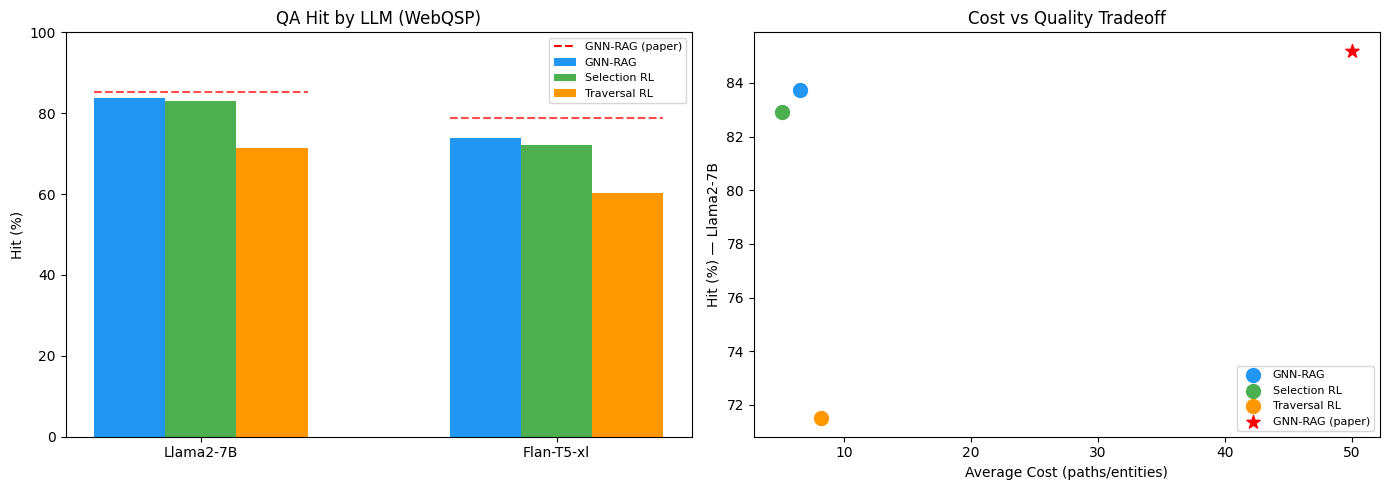

Saved figure to /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/p6_llm_eval/p6_comparison_plots.png

=== ERROR ANALYSIS ===

Selection RL vs GNN-RAG (per question):
  Selection RL wins: 28 (1.7%)
  GNN-RAG wins:      39 (2.4%)
  Ties:              1572 (95.9%)

--- Examples: Selection RL wins ---
  Q: what year was albert pujols rookie year
    Gold: ['2001 Major League Baseball Season']
    GNN-RAG: "Based on the reasoning paths provided, the possible answers for Albert Pujols' r" (paths=14)
    Sel RL:  "Based on the reasoning paths provided, the possible answers for Albert Pujols' r" (paths=10)
  Q: who won the 2000 fa cup final
    Gold: ['Chelsea F.C.']
    GNN-RAG: "Based on the reasoning paths provided, the answer to the question "Who won the 2" (paths=27)
    Sel RL:  "Based on the reasoning paths provided, the possible answers to the question "who" (paths=10)
  Q: who did cher have a son with
    Gold: ['Gregg Allman', 'Sonny Bono']
    GNN-RAG: "Based on th

In [37]:
# === Cell 11: Visualization & Analysis ===
import matplotlib.pyplot as plt

def load_predictions(pred_file):
    if not os.path.exists(pred_file):
        return {}
    with open(pred_file) as f:
        preds = [json.loads(l) for l in f if l.strip()]
    by_method = {}
    for p in preds:
        by_method.setdefault(p.get('method', 'unknown'), []).append(p)
    return by_method


# --- 1. Bar chart: Hit comparison ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

llm_files = {
    'Llama2-7B': PRED_FILE_LLAMA,
    'Flan-T5-xl': PRED_FILE_FLAN,
    'ChatGPT': PRED_FILE_GPT,
}

method_names = {'gnn_rag': 'GNN-RAG', 'selection_rl': 'Selection RL', 'traversal_rl': 'Traversal RL'}
colors = {'gnn_rag': '#2196F3', 'selection_rl': '#4CAF50', 'traversal_rl': '#FF9800'}

# Paper baselines
paper_hit = {'Llama2-7B': 85.2, 'ChatGPT': 85.3, 'Flan-T5-xl': 78.9}

hit_data = {}  # {llm: {method: hit}}
cost_data = {}  # {method: avg_cost}

for llm_name, pred_file in llm_files.items():
    by_method = load_predictions(pred_file)
    if not by_method:
        continue
    hit_data[llm_name] = {}
    for method, preds in by_method.items():
        metrics = evaluate_predictions(preds)
        hit_data[llm_name][method] = metrics['hit']
        if method not in cost_data:
            cost_data[method] = np.mean([p['cost'] for p in preds])

# Plot Hit by LLM
ax = axes[0]
if hit_data:
    x_labels = list(hit_data.keys())
    x = np.arange(len(x_labels))
    width = 0.2

    for i, method in enumerate(['gnn_rag', 'selection_rl', 'traversal_rl']):
        vals = [hit_data.get(llm, {}).get(method, 0) for llm in x_labels]
        ax.bar(x + i * width, vals, width, label=method_names.get(method, method),
               color=colors.get(method, 'gray'))

    # Paper baseline line
    for i, llm in enumerate(x_labels):
        if llm in paper_hit:
            ax.plot([i - 0.1, i + 0.5], [paper_hit[llm], paper_hit[llm]],
                    'r--', linewidth=1.5, alpha=0.7)
    ax.plot([], [], 'r--', label='GNN-RAG (paper)')  # Legend entry

    ax.set_xticks(x + width)
    ax.set_xticklabels(x_labels)
    ax.set_ylabel('Hit (%)')
    ax.set_title('QA Hit by LLM (WebQSP)')
    ax.legend(fontsize=8)
    ax.set_ylim(0, 100)
else:
    ax.text(0.5, 0.5, 'No results yet', ha='center', va='center', transform=ax.transAxes)
    ax.set_title('QA Hit by LLM')

# --- 2. Cost vs Hit scatter (Pareto frontier) ---
ax = axes[1]
if hit_data and cost_data:
    # Use first available LLM for cost-quality tradeoff
    llm_name = list(hit_data.keys())[0]
    for method in ['gnn_rag', 'selection_rl', 'traversal_rl']:
        if method in hit_data[llm_name] and method in cost_data:
            ax.scatter(cost_data[method], hit_data[llm_name][method],
                      s=100, c=colors.get(method, 'gray'),
                      label=method_names.get(method, method), zorder=5)

    # Paper baseline
    if llm_name in paper_hit:
        ax.scatter(50, paper_hit[llm_name], s=100, c='red', marker='*',
                  label='GNN-RAG (paper)', zorder=5)

    ax.set_xlabel('Average Cost (paths/entities)')
    ax.set_ylabel(f'Hit (%) — {llm_name}')
    ax.set_title('Cost vs Quality Tradeoff')
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, 'No results yet', ha='center', va='center', transform=ax.transAxes)
    ax.set_title('Cost vs Quality Tradeoff')

plt.tight_layout()
fig_path = os.path.join(P6_DIR, 'p6_comparison_plots.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved figure to {fig_path}')


# --- 3. Error Analysis: GRL-RAG vs GNN-RAG ---
print('\n' + '='*80)
print('=== ERROR ANALYSIS ===')
print('='*80)

# Compare per-question: where does Selection RL beat/lose to GNN-RAG?
first_llm_file = None
for f in [PRED_FILE_LLAMA, PRED_FILE_FLAN, PRED_FILE_GPT]:
    if os.path.exists(f):
        first_llm_file = f
        break

if first_llm_file:
    by_method = load_predictions(first_llm_file)

    if 'gnn_rag' in by_method and 'selection_rl' in by_method:
        gnn_preds = {p['id']: p for p in by_method['gnn_rag']}
        sel_preds = {p['id']: p for p in by_method['selection_rl']}

        common_ids = set(gnn_preds.keys()) & set(sel_preds.keys())

        sel_wins, gnn_wins, ties = 0, 0, 0
        sel_win_examples, gnn_win_examples = [], []

        for qid in common_ids:
            gnn_hit = eval_hit(gnn_preds[qid]['prediction'], gnn_preds[qid]['ground_truth'])
            sel_hit = eval_hit(sel_preds[qid]['prediction'], sel_preds[qid]['ground_truth'])

            if sel_hit > gnn_hit:
                sel_wins += 1
                if len(sel_win_examples) < 3:
                    sel_win_examples.append((qid, gnn_preds[qid], sel_preds[qid]))
            elif gnn_hit > sel_hit:
                gnn_wins += 1
                if len(gnn_win_examples) < 3:
                    gnn_win_examples.append((qid, gnn_preds[qid], sel_preds[qid]))
            else:
                ties += 1

        print(f'\nSelection RL vs GNN-RAG (per question):')
        print(f'  Selection RL wins: {sel_wins} ({100*sel_wins/len(common_ids):.1f}%)')
        print(f'  GNN-RAG wins:      {gnn_wins} ({100*gnn_wins/len(common_ids):.1f}%)')
        print(f'  Ties:              {ties} ({100*ties/len(common_ids):.1f}%)')

        if sel_win_examples:
            print('\n--- Examples: Selection RL wins ---')
            for qid, gnn_p, sel_p in sel_win_examples:
                print(f'  Q: {gnn_p["question"]}')
                print(f'    Gold: {gnn_p["ground_truth"]}')
                print(f'    GNN-RAG: "{gnn_p["prediction"][:80]}" (paths={gnn_p["n_paths"]})')
                print(f'    Sel RL:  "{sel_p["prediction"][:80]}" (paths={sel_p["n_paths"]})')

        if gnn_win_examples:
            print('\n--- Examples: GNN-RAG wins ---')
            for qid, gnn_p, sel_p in gnn_win_examples:
                print(f'  Q: {gnn_p["question"]}')
                print(f'    Gold: {gnn_p["ground_truth"]}')
                print(f'    GNN-RAG: "{gnn_p["prediction"][:80]}" (paths={gnn_p["n_paths"]})')
                print(f'    Sel RL:  "{sel_p["prediction"][:80]}" (paths={sel_p["n_paths"]})')
    else:
        print('Need both gnn_rag and selection_rl predictions for error analysis.')
else:
    print('No prediction files found. Run LLM inference cells first.')

print('\nP6 evaluation complete.')

In [38]:
# === Cell 12: Export Results → JSON for P5 ===
# Generate JSON files that P5 expects for auto-filling tables and figures.

def load_all_preds(pred_file):
    if not os.path.exists(pred_file):
        return {}
    with open(pred_file) as f:
        preds = [json.loads(l) for l in f if l.strip()]
    by_method = {}
    for p in preds:
        by_method.setdefault(p.get('method'), []).append(p)
    return by_method


for method, p5_filename in [
    ('gnn_rag', 'gnn_rag_webqsp.json'),
    ('selection_rl', 'grl_selection_webqsp.json'),
    ('traversal_rl', 'grl_traversal_webqsp.json'),
]:
    results = retrieval_results[method]
    costs = [r['cost'] for r in results.values()]

    # Retrieval-level metrics
    hits_list, f1_list = [], []
    for qid, r in results.items():
        path_text = ' '.join(r['paths'])
        hits_list.append(eval_hit(path_text, r['answers']))
        pred_list = r['paths'] if r['paths'] else ['']
        f1_val, _, _ = eval_f1(pred_list, r['answers'])
        f1_list.append(f1_val)

    summary = {
        'method': method,
        'dataset': 'webqsp',
        'n_questions': len(results),
        'summary': {
            'hits': float(np.mean(hits_list)),
            'f1': float(np.mean(f1_list)),
            'cost': float(np.mean(costs)),
        },
        'qa_results': {},
    }

    # Add LLM QA results
    for llm_name, pred_file in [('llama2', PRED_FILE_LLAMA), ('flan_t5', PRED_FILE_FLAN), ('chatgpt', PRED_FILE_GPT)]:
        by_method_preds = load_all_preds(pred_file)
        if method in by_method_preds:
            metrics = evaluate_predictions(by_method_preds[method])
            summary['qa_results'][llm_name] = metrics

    filepath = os.path.join(RESULTS_DIR, p5_filename)
    with open(filepath, 'w') as f:
        json.dump(summary, f, indent=2)
    print(f'Saved: {filepath}')

# GreedyGNN baseline (from P4b)
greedy_path = os.path.join(RESULTS_DIR, 'greedy_gnn_webqsp.json')
greedy_summary = {
    'method': 'greedy_gnn',
    'dataset': 'webqsp',
    'summary': {
        'hits': 0.6580,
        'f1': 0.0776,
        'cost': 49.9,
    },
}
with open(greedy_path, 'w') as f:
    json.dump(greedy_summary, f, indent=2)
print(f'Saved: {greedy_path}')

print('\nAll result files exported for P5.')

  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
Saved: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/gnn_rag_webqsp.json
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
Saved: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/grl_selection_webqsp.json
  (skipped 11 questions with empty answers)
  (skipped 11 questions with empty answers)
Saved: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/grl_traversal_webqsp.json
Saved: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/greedy_gnn_webqsp.json

All result files exported for P5.
